This file is to explore the data and have an easy visualisation. 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('data/raw.csv')
df.head()

,timestamp,kwh
0,2026-01-01 00:00:00,29.943
1,2026-01-01 01:00:00,30.081
2,2026-01-01 02:00:00,31.011
3,2026-01-01 03:00:00,29.547
4,2026-01-01 04:00:00,30.343


In [ ]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 6984 entries, 0 to 6983
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  6984 non-null   str    
 1   kwh        6984 non-null   float64
dtypes: float64(1), str(1)
memory usage: 109.3 KB


In [6]:
df.describe()

,kwh
count,6984.000000
mean,60.053425
std,30.839341
min,18.721000
25%,26.655500
50%,66.436500
75%,84.908000
max,141.598000


Checking for lacking values and duplicates

In [ ]:
print(f"Temporal spread : from {df['timestamp'].min()} to {df['timestamp'].max()}")
print(f"total points : {len(df)}")
print(f"Lacking values (kWh = 0 ) : {df['kwh'].isnull().sum()}")
print(f"Timestamps ducplicates: {df['timestamp'].duplicated().sum()}")

Temporal spread : from 2026-01-01 00:00:00 to 2026-10-18 23:00:00
total points : 6984
Lacking values (kWh = 0 ) : 0
Timestamp ducplicates: 0


In [28]:
time_diffs = df['timestamp'].diff()
gaps = time_diffs[time_diffs > pd.Timedelta(hours=1)]
print(f"Breaks in the sequence : {len(gaps)}")

Breaks in the sequence : 0


Representation of the data

In [ ]:
df['hour'] = df['timestamp'].dt.hour
df['dayofweek'] = df['timestamp'].dt.dayofweek
df['is_weekend'] = df['dayofweek'] >= 5


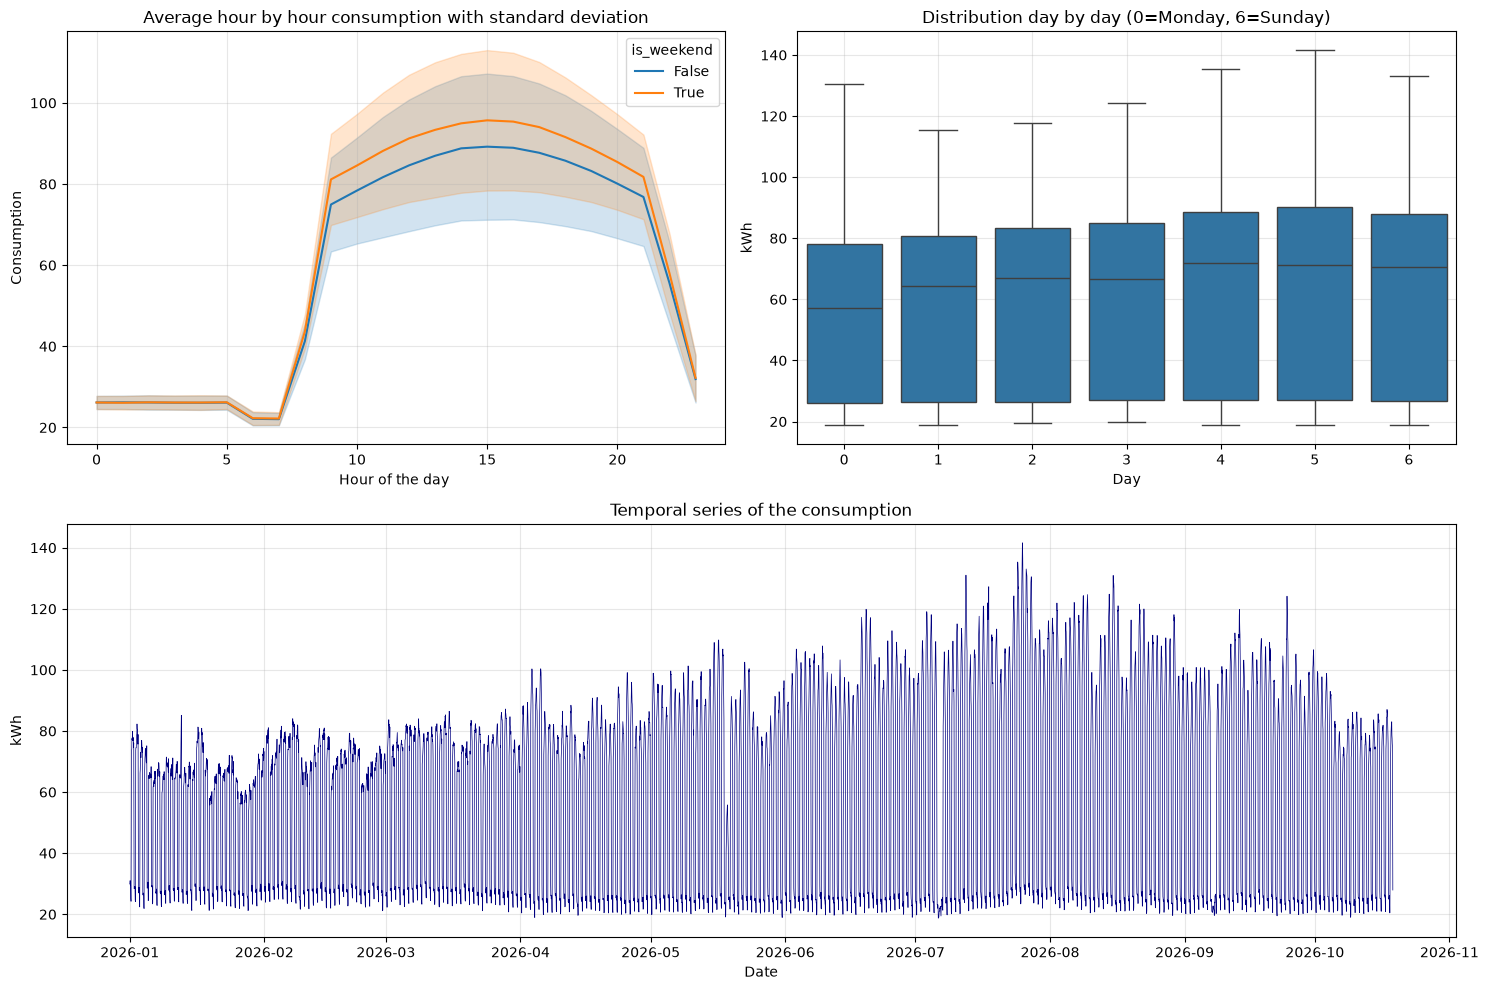

In [22]:
plt.figure(figsize=(15, 10))


plt.subplot(2, 2, 1)
sns.lineplot(data=df, x='hour', y='kwh', hue='is_weekend', errorbar='sd')
plt.title('Average hour by hour consumption with standard deviation')
plt.xlabel('Hour of the day ')
plt.ylabel('Consumption')
plt.grid(True, alpha=0.3)


plt.subplot(2, 2, 2)
sns.boxplot(data=df, x='dayofweek', y='kwh')
plt.title('Distribution day by day (0=Monday, 6=Sunday)')
plt.xlabel('Day')
plt.ylabel('kWh')
plt.grid(True, alpha=0.3)


plt.subplot(2, 1, 2)
plt.plot(df['timestamp'], df['kwh'], linewidth=0.5, color='navy')
plt.title('Temporal series of the consumption')
plt.xlabel('Date')
plt.ylabel('kWh')
plt.grid(True, alpha=0.3)

plt.tight_layout()
#plt.savefig('eda_summary.png', dpi=300)
plt.show()

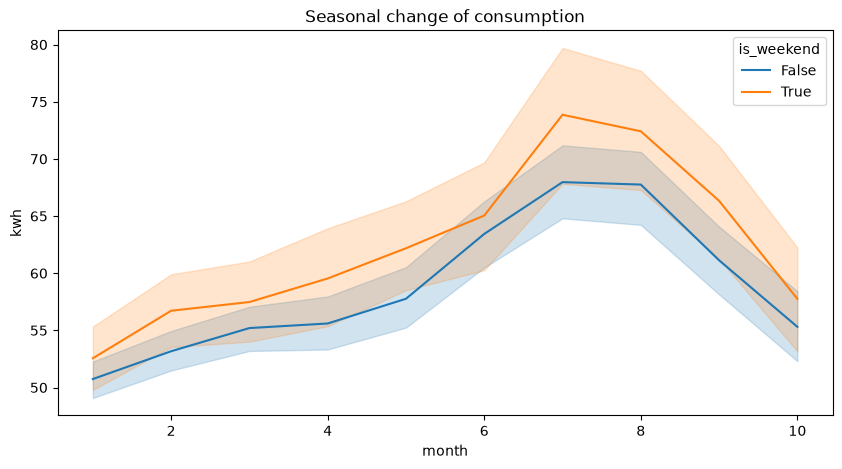

In [27]:
df['month'] = df['timestamp'].dt.month

plt.figure(figsize=(10, 5))

sns.lineplot(df, x='month',y='kwh',hue='is_weekend')
plt.title("Seasonal change of consumption")
plt.show()